# Computer Vision Laboratory
## Experiment 4: Edge Detection using DoG, LoG and Canny

**Student Name:** YASHASWINI B SURESH  

**USN:** 1RUA24CSE0548

**Date:** 03-11-2026

### 1. Aim
To implement and compare Difference of Gaussians (DoG), Laplacian of Gaussian (LoG) and Canny edge detection, and observe how each method identifies significant intensity changes in a grayscale image.

### 2. Software Requirements
Python 3.x, OpenCV, NumPy, Matplotlib, scikit-image

`pip install opencv-python numpy matplotlib scikit-image`

### 3. Theory (short)
- **DoG** = (G(kσ) − G(σ)) * I : difference of two Gaussian-smoothed images; fast approximation of LoG.
- **LoG** = ∇²(G * I) : Gaussian smoothing followed by the Laplacian (second derivative).
- **Canny** : Gaussian smoothing → gradient → non-maximum suppression → double threshold → hysteresis.

In [1]:
pip install opencv-python numpy matplotlib scikit-image

### 4. Implementation (main program)

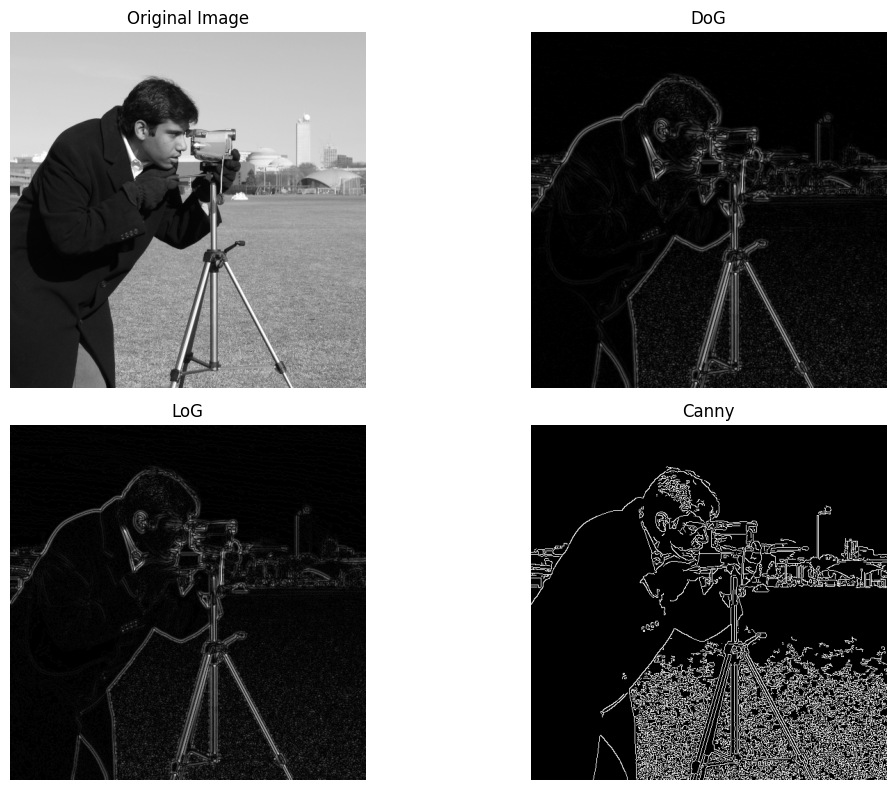

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale image
image = data.camera().astype(np.uint8)

# ---------------- DoG ----------------
sigma1 = 1.0
sigma2 = 2.0
g1 = cv2.GaussianBlur(image, (0, 0), sigma1)
g2 = cv2.GaussianBlur(image, (0, 0), sigma2)
dog = cv2.absdiff(g1, g2)
dog_display = cv2.normalize(dog, None, 0, 255, cv2.NORM_MINMAX)

# ---------------- LoG ----------------
sigma = 1.2
blur = cv2.GaussianBlur(image, (0, 0), sigma)
laplacian = cv2.Laplacian(blur, cv2.CV_64F)
log_display = cv2.normalize(np.abs(laplacian), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# ---------------- Canny ----------------
low_threshold = 50
high_threshold = 150
canny = cv2.Canny(image, low_threshold, high_threshold)

# ---------------- Display ----------------
plt.figure(figsize=(12, 8))
for i, (img, t) in enumerate([(image, "Original Image"), (dog_display, "DoG"),
                              (log_display, "LoG"), (canny, "Canny")], 1):
    plt.subplot(2, 2, i)
    plt.imshow(img, cmap="gray")
    plt.title(t)
    plt.axis("off")
plt.tight_layout()
plt.show()

### 5. Student Task 1 – DoG with σ1 = 1.0, σ2 = 2.0 vs σ1 = 1.0, σ2 = 3.0

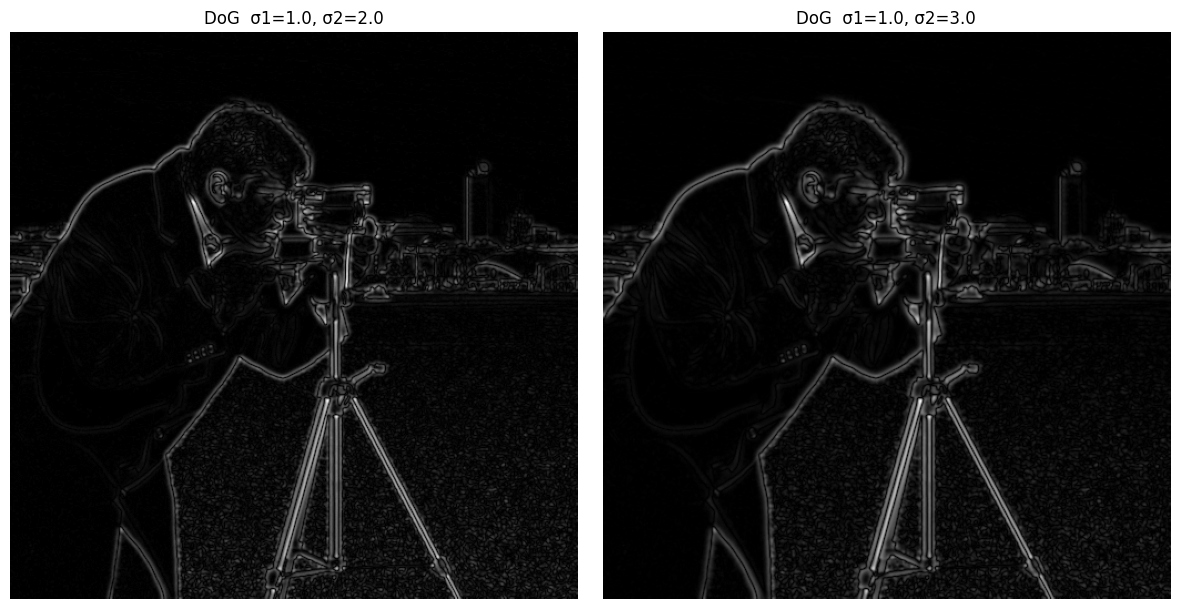

Mean raw DoG response (σ2=2.0): 2.85
Mean raw DoG response (σ2=3.0): 4.69


In [3]:
def compute_dog(img, s1, s2):
    a = cv2.GaussianBlur(img, (0, 0), s1)
    b = cv2.GaussianBlur(img, (0, 0), s2)
    return cv2.normalize(cv2.absdiff(a, b), None, 0, 255, cv2.NORM_MINMAX)

dog_a = compute_dog(image, 1.0, 2.0)
dog_b = compute_dog(image, 1.0, 3.0)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1); plt.imshow(dog_a, cmap="gray"); plt.title("DoG  σ1=1.0, σ2=2.0"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(dog_b, cmap="gray"); plt.title("DoG  σ1=1.0, σ2=3.0"); plt.axis("off")
plt.tight_layout(); plt.show()

raw_a = cv2.absdiff(cv2.GaussianBlur(image,(0,0),1.0), cv2.GaussianBlur(image,(0,0),2.0))
raw_b = cv2.absdiff(cv2.GaussianBlur(image,(0,0),1.0), cv2.GaussianBlur(image,(0,0),3.0))
print("Mean raw DoG response (σ2=2.0):", round(raw_a.mean(), 3))
print("Mean raw DoG response (σ2=3.0):", round(raw_b.mean(), 3))

**Observation (Task 1):** Increasing σ2 from 2.0 to 3.0 widens the gap between the two scales. The mean DoG response rises (about 2.85 → 4.69) and the response becomes broader and blurrier, emphasising larger structures and thick object boundaries. The finest details (small textures, thin lines) become less sharp. With σ2 = 2.0 the edges are thinner and finer details are better preserved.

### 6. Student Task 2 – LoG with σ = 1.2 vs σ = 2.0

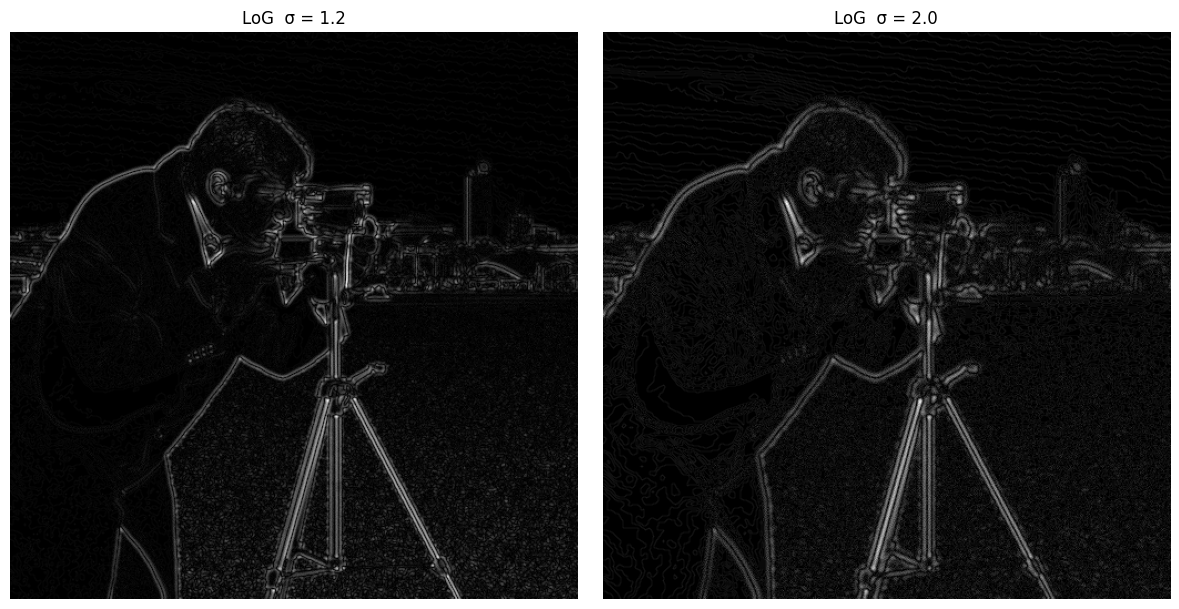

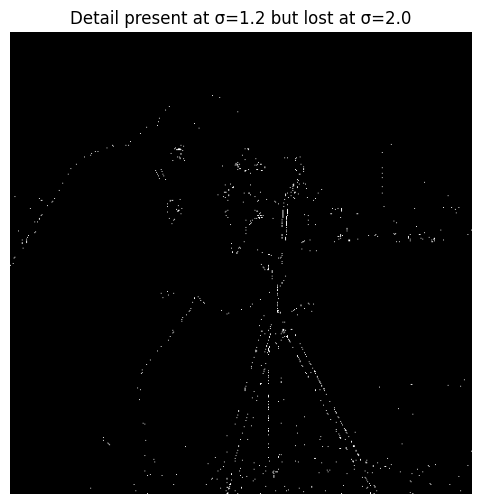

In [4]:
def compute_log(img, s):
    b = cv2.GaussianBlur(img, (0, 0), s)
    lap = cv2.Laplacian(b, cv2.CV_64F)
    return cv2.normalize(np.abs(lap), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

log_a = compute_log(image, 1.2)
log_b = compute_log(image, 2.0)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1); plt.imshow(log_a, cmap="gray"); plt.title("LoG  σ = 1.2"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(log_b, cmap="gray"); plt.title("LoG  σ = 2.0"); plt.axis("off")
plt.tight_layout(); plt.show()

# Fine detail that disappears = pixels strong at σ=1.2 but weak at σ=2.0
lost = ((log_a > 60) & (log_b < 30)).astype(np.uint8) * 255
plt.figure(figsize=(6, 6)); plt.imshow(lost, cmap="gray"); plt.title("Detail present at σ=1.2 but lost at σ=2.0"); plt.axis("off"); plt.show()

**Observation (Task 2):** With σ = 2.0 the fine details disappear: the texture of the grass in the background, the small edges on the camera and tripod, face features of the cameraman, and noise-like fine-scale variations. Only the major, large-scale boundaries (coat, camera body, building outline) remain. A larger σ means stronger smoothing, so it suppresses noise but also loses fine detail and localises edges less precisely.

### 7. Student Task 3 – Canny with thresholds (30,100), (50,150), (100,200)

Thresholds ( 30,100) -> edge pixels =  38878  (14.83% of image)
Thresholds ( 50,150) -> edge pixels =  30980  (11.82% of image)
Thresholds (100,200) -> edge pixels =  19686  (7.51% of image)


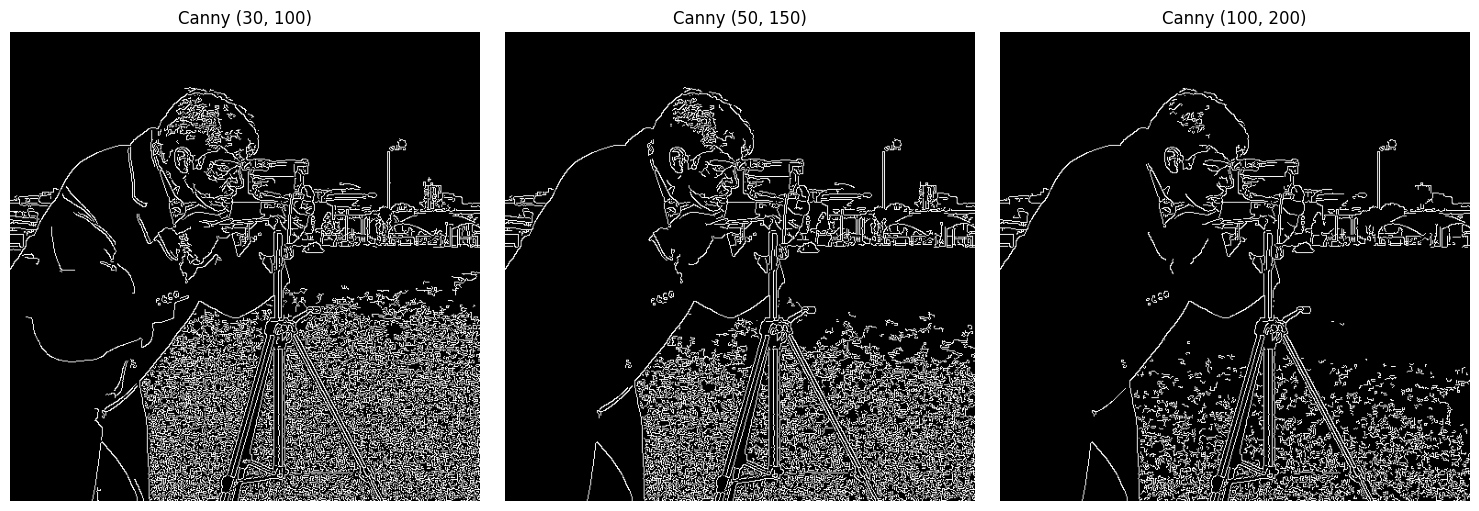

In [5]:
thresholds = [(30, 100), (50, 150), (100, 200)]

plt.figure(figsize=(15, 5))
for i, (lo, hi) in enumerate(thresholds, 1):
    e = cv2.Canny(image, lo, hi)
    plt.subplot(1, 3, i)
    plt.imshow(e, cmap="gray")
    plt.title(f"Canny ({lo}, {hi})")
    plt.axis("off")
    print(f"Thresholds ({lo:3d},{hi:3d}) -> edge pixels = {np.count_nonzero(e):6d}  "
          f"({100*np.count_nonzero(e)/e.size:.2f}% of image)")
plt.tight_layout(); plt.show()

**Observation (Task 3):**

| Thresholds | Edge pixels | Behaviour |
|---|---|---|
| (30, 100) | ≈ 38,878 (14.8%) | Most edges, including weak texture in the grass and many false/noisy edges |
| (50, 150) | ≈ 30,980 (11.8%) | Balanced: main contours kept, moderate texture |
| (100, 200) | ≈ 19,686 (7.5%) | Only strong edges; clean but some weak real edges (e.g. background details) are lost |

Lower thresholds keep more weak edges (more detail, more false edges); higher thresholds keep only strong edges (cleaner, but can break real edges).

### 8. Noise sensitivity test (supports the observation table)

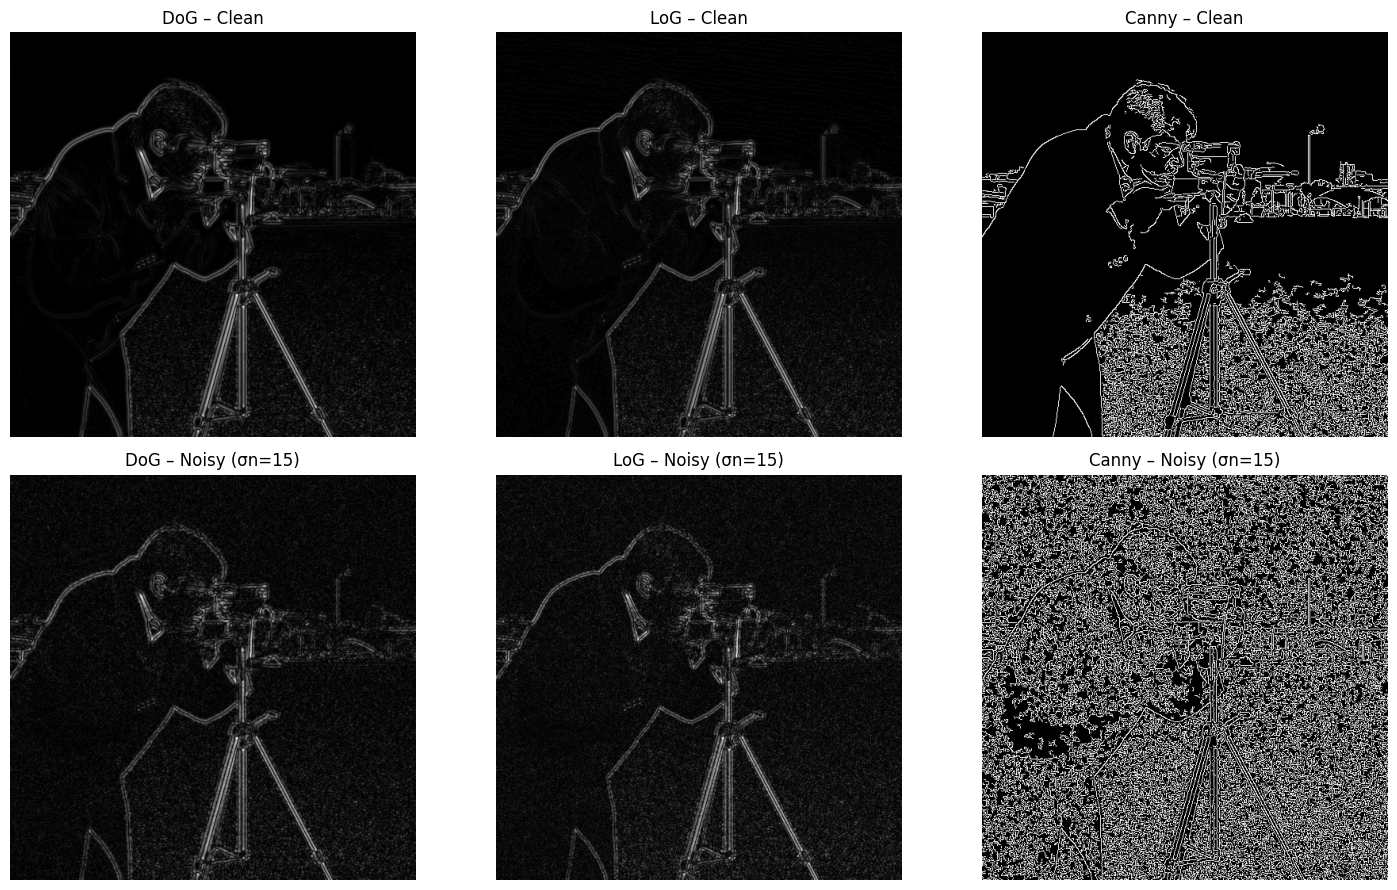

Canny edge pixels  clean: 30980 | noisy: 85640


In [6]:
rng = np.random.default_rng(0)
noisy = np.clip(image + rng.normal(0, 15, image.shape), 0, 255).astype(np.uint8)

def dog_raw(img):  return cv2.normalize(cv2.absdiff(cv2.GaussianBlur(img,(0,0),1.0), cv2.GaussianBlur(img,(0,0),2.0)), None,0,255,cv2.NORM_MINMAX)
def log_raw(img):  return compute_log(img, 1.2)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for r, (im, name) in enumerate([(image, "Clean"), (noisy, "Noisy (σn=15)")]):
    ax[r,0].imshow(dog_raw(im), cmap="gray");     ax[r,0].set_title(f"DoG – {name}")
    ax[r,1].imshow(log_raw(im), cmap="gray");     ax[r,1].set_title(f"LoG – {name}")
    ax[r,2].imshow(cv2.Canny(im,50,150), cmap="gray"); ax[r,2].set_title(f"Canny – {name}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

print("Canny edge pixels  clean:", np.count_nonzero(cv2.Canny(image,50,150)),
      "| noisy:", np.count_nonzero(cv2.Canny(noisy,50,150)))

### 9. Observation Table

| Method | Edge thickness | Noise sensitivity | Continuity | Remarks |
|---|---|---|---|---|
| **DoG** | Thick, soft/blurry bands (width depends on σ1, σ2) | Moderate – band-pass filter, suppresses very fine noise but responds to texture | Good; smooth, continuous responses | Grey-level response (not binary); fast approximation of LoG |
| **LoG** | Medium; double-edge response around each edge | High – second derivative amplifies noise, needs a good σ | Moderate; can produce closed contours (zero-crossings) but noisy spots | Isotropic (direction-independent); detects fine details at small σ |
| **Canny** | Thin, 1-pixel wide | Low (after smoothing + hysteresis), but low thresholds add false edges | Best; hysteresis links weak edges to strong ones | Binary, well-localised, directly usable edge map |

### 10. Student Task 4 – Three observations comparing DoG, LoG and Canny
1. **Output type / thickness:** DoG and LoG give grey-level responses with thick, blurry edge bands, while Canny gives thin, 1-pixel binary edge contours.
2. **Noise & detail:** LoG (second derivative) is the most sensitive to noise and fine texture; DoG is smoother since it is a band-pass difference of two blurs; Canny controls noise using Gaussian smoothing, non-maximum suppression and hysteresis.
3. **Continuity & usability:** Canny edges are the most continuous and well-localised and are directly usable for later steps (shape analysis, segmentation), whereas DoG/LoG outputs need thresholding / zero-crossing detection first.

### 11. Student Task 5 – Why is Gaussian smoothing useful before derivative-based edge detection?
Derivative operators (gradient, Laplacian) amplify high-frequency content, and image noise is high-frequency. Without smoothing, noise pixels produce strong false edge responses. A Gaussian filter removes noise before differentiation, gives a controllable scale (σ) at which edges are detected, is isotropic, and does not introduce ringing. Result: fewer false edges and more stable, reliable edge detection.

### 12. Viva Questions with Answers
1. **What is an edge?** A location where image intensity (or colour) changes sharply, usually at object or region boundaries.
2. **Why smooth before edge detection?** Derivatives amplify noise; Gaussian smoothing reduces noise and selects the scale of edges.
3. **First vs second derivative?** First derivative (gradient) has a *peak* at the edge; second derivative (Laplacian) has a *zero-crossing* at the edge and is more noise-sensitive.
4. **DoG vs LoG?** LoG applies the Laplacian to a Gaussian-smoothed image; DoG subtracts two Gaussian-smoothed images of different σ.
5. **Why is DoG an approximation of LoG?** G(kσ) − G(σ) ≈ (k − 1)σ²∇²G, so the difference of Gaussians approximates the Laplacian of Gaussian (with k close to 1) and is cheaper to compute.
6. **Purpose of non-maximum suppression?** Thins wide gradient ridges to 1-pixel edges by keeping only local maxima along the gradient direction.
7. **Why two thresholds in Canny?** To separate strong edges (sure), weak edges (candidates) and non-edges, giving better noise rejection and continuity than a single threshold.
8. **Hysteresis?** Weak edge pixels are kept only if connected to strong edge pixels; otherwise discarded.
9. **Thresholds too low?** Many false edges and noise edges appear; edges become cluttered.
10. **Which gives the most usable thin binary edge map?** Canny.

### 13. Result
DoG, LoG and Canny edge detection were implemented successfully in Python (OpenCV). Their outputs were compared by varying σ values and Canny thresholds, and the effects on edge thickness, noise, continuity and fine details were observed. Canny gave the thinnest, most continuous binary edges, LoG was the most noise-sensitive, and DoG gave smooth, blurry responses that approximate LoG.

*Note: Hough Transform is intentionally not included in Experiment 4.*